# Part 4 · The other ensemble methods: voting, bagging, boosting, stacking

**Workshop: Many models, one forecast** · about 10 minutes · every cell runs in a few seconds on a laptop.

The tutorial (`01_tutorial_ocean_ensemble.ipynb`) covered the two methods our project uses: deep ensembles (seeds) and averaging. This notebook shows the other classic families in scikit-learn, on small synthetic datasets so we can focus on the ideas.

| Step | Method | The idea | Checkpoint: you should see |
|---|---|---|---|
| 1 | Why averaging works | The variance formula, simulated | dots on the lines; curves flatten at ρ |
| 2 | Voting | Different models vote, hard or soft | soft voting `0.890`, average member `0.882` |
| 3 | **Bagging** and random forests | Same model, random resamples of the data | one deep tree `0.836`, random forest `0.885` |
| 4 | **Boosting** | Weak models, each fixing the previous errors | one stump `0.798`, gradient boosting `0.887` |
| 5 | **Stacking** | A meta-model learns whom to trust | stacking `0.870` beats every member; the leakage trap `0.767` vs `0.891` |

Run the cells from top to bottom with **Shift + Enter** and compare with the ✅ checkpoints. It is saved with outputs, so you can also just read it. Accuracies can differ in the 3rd decimal on another machine.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_classification
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, RandomForestClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier, GradientBoostingRegressor,
                              StackingClassifier)

BLUE, ORANGE, NAVY, GREY = "#1F6F9F", "#C55A23", "#12263A", "#8A94A3"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Repeated cross-validation: a single train/test split is too noisy to compare models that are this close
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
results = []   # every score we compute ends up in the summary table at the end

def evaluate(name, model, X, y, part):
    scores = cross_val_score(model, X, y, cv=CV, n_jobs=-1)
    results.append({"part": part, "model": name, "accuracy": scores.mean(), "std": scores.std()})
    print(f"{name:28s} {scores.mean():.3f} ± {scores.std():.3f}")
    return scores.mean()

def plot_boundary(model, X, y, ax, title):
    # Fit on all points and colour the plane by the predicted probability of class 1
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250),
                         np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    proba = model.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=20, cmap="RdBu_r", alpha=.55, vmin=0, vmax=1)
    ax.contour(xx, yy, proba, levels=[.5], colors=NAVY, linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", s=8, edgecolor="none", alpha=.8)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

## 1 · Why averaging works

Take $M$ models whose errors each have variance $\sigma^2$ and pairwise correlation $\rho$. The variance of their **average** is

$$\operatorname{Var}(\bar{e}) = \rho\,\sigma^2 + \frac{(1-\rho)\,\sigma^2}{M}$$

Let's check that with a simulation: draw correlated errors, average them, and measure the variance that is left.

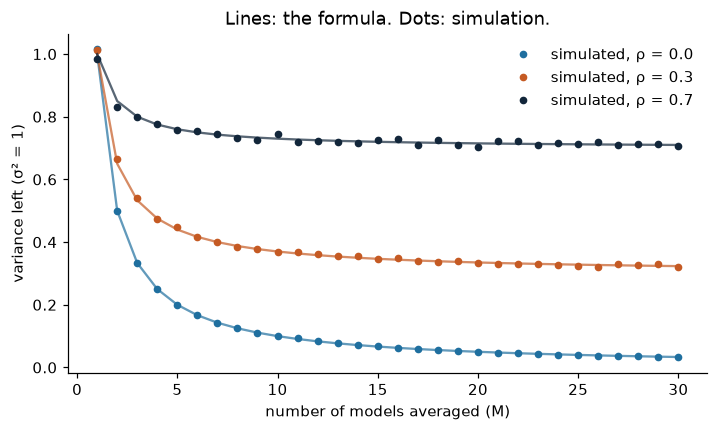

In [2]:
rng = np.random.default_rng(0)

def simulated_variance(M, rho, trials=20_000):
    # M errors with variance 1 and pairwise correlation rho: a shared part plus an individual part
    shared = rng.standard_normal((trials, 1))
    own = rng.standard_normal((trials, M))
    errors = np.sqrt(rho) * shared + np.sqrt(1 - rho) * own
    return errors.mean(axis=1).var()

Ms = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(7.5, 4))
for rho, color in [(0.0, BLUE), (0.3, ORANGE), (0.7, NAVY)]:
    ax.plot(Ms, [simulated_variance(M, rho) for M in Ms], "o", color=color, ms=4, label=f"simulated, ρ = {rho}")
    ax.plot(Ms, rho + (1 - rho) / Ms, "-", color=color, lw=1.5, alpha=.7)
ax.set_xlabel("number of models averaged (M)"); ax.set_ylabel("variance left (σ² = 1)")
ax.set_title("Lines: the formula. Dots: simulation."); ax.legend(frameon=False)
plt.show()

✅ **Checkpoint 1:** the dots (simulation) sit on the lines (formula).

**Read the plot:** the curves flatten at $\rho$. With correlated models, adding more of them stops helping quickly.
The way down is *diversity*: models that are each good but make **different** mistakes.

## 2 · Voting

Our running dataset for parts 2–4: two interleaving half-moons with a lot of label noise.

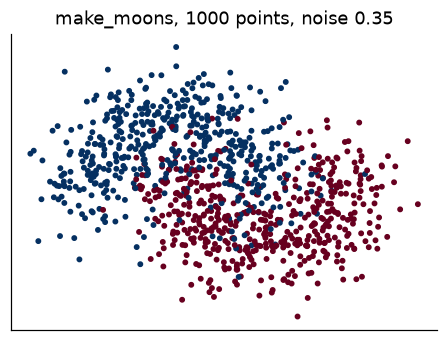

In [3]:
X, y = make_moons(n_samples=1000, noise=0.35, random_state=0)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", s=8)
ax.set_title("make_moons, 1000 points, noise 0.35"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

Three very different learners: a (polynomial) logistic regression, a decision tree and k-nearest neighbours.
**Hard voting** counts their labels; **soft voting** averages their predicted probabilities.

In [4]:
members = [
    ("logistic (poly 3)", make_pipeline(PolynomialFeatures(3), StandardScaler(), LogisticRegression(max_iter=2000))),
    ("decision tree",     DecisionTreeClassifier(max_depth=5, random_state=0)),
    ("k-NN (k=25)",       KNeighborsClassifier(25)),
]
member_scores = [evaluate(name, m, X, y, "2 voting") for name, m in members]
print("-" * 45)
evaluate("hard voting", VotingClassifier(members, voting="hard"), X, y, "2 voting")
evaluate("soft voting", VotingClassifier(members, voting="soft"), X, y, "2 voting")
print(f"\naverage member: {np.mean(member_scores):.3f}   best member: {max(member_scores):.3f}")

logistic (poly 3)            0.882 ± 0.023
decision tree                0.872 ± 0.025
k-NN (k=25)                  0.891 ± 0.021
---------------------------------------------
hard voting                  0.887 ± 0.022
soft voting                  0.890 ± 0.020

average member: 0.882   best member: 0.891


✅ **Checkpoint 2:** `hard voting 0.887`, `soft voting 0.890`, `average member: 0.882`, `best member: 0.891`.

The ensemble beats the *average* member and lands close to the best one, **without us having to know in advance which member is best**.
On this easy 2-D problem all three members are already near the limit set by the label noise, so there isn't much room left.
Look at how the decision boundaries combine:

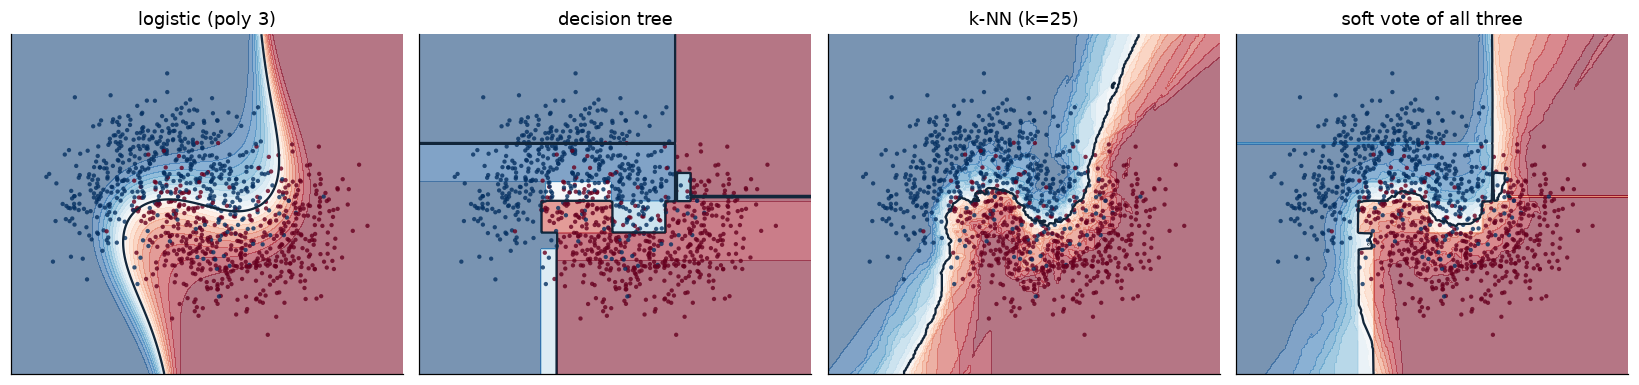

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, model) in zip(axes, members):
    plot_boundary(model, X, y, ax, name)
plot_boundary(VotingClassifier(members, voting="soft"), X, y, axes[3], "soft vote of all three")
plt.tight_layout(); plt.show()

## 3 · Bagging and random forests

A fully grown decision tree is the textbook **high-variance** model: it memorises the noise.
Bagging trains many trees on bootstrap samples and averages them. A random forest also restricts every split to a random subset of features, which makes the trees less alike (lower $\rho$).

one deep tree                0.836 ± 0.021
bagging, 100 trees           0.875 ± 0.015


random forest, 100 trees     0.885 ± 0.019


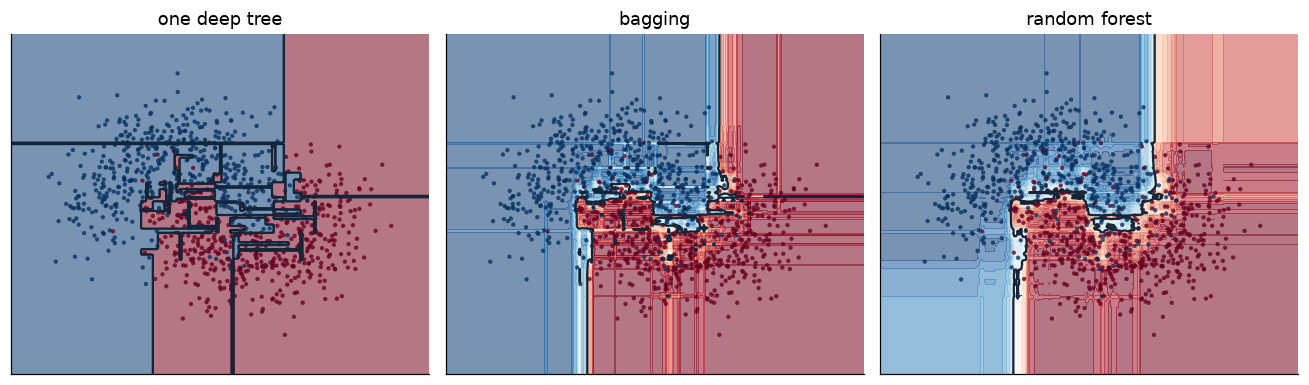

In [6]:
single_tree = DecisionTreeClassifier(random_state=0)
bagging     = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0)
forest      = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=0)

evaluate("one deep tree", single_tree, X, y, "3 bagging")
evaluate("bagging, 100 trees", bagging, X, y, "3 bagging")
evaluate("random forest, 100 trees", forest, X, y, "3 bagging")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, model, name in zip(axes, [single_tree, bagging, forest], ["one deep tree", "bagging", "random forest"]):
    plot_boundary(model, X, y, ax, name)
plt.tight_layout(); plt.show()

✅ **Checkpoint 3:** `one deep tree 0.836`, `bagging 0.875`, `random forest 0.885`.

The single tree draws jagged islands around noisy points. Averaging 100 of them smooths the boundary.

**Free validation:** each tree never saw ~37% of the rows (its *out-of-bag* rows). Scoring every row with only the trees that didn't train on it gives an honest estimate without a separate validation set. Watch it as we add trees:

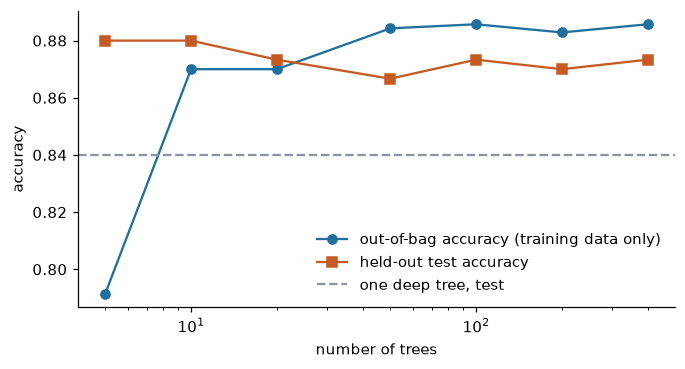

In [7]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
sizes = [5, 10, 20, 50, 100, 200, 400]
oob, test = [], []
for n in sizes:
    rf = RandomForestClassifier(n_estimators=n, min_samples_leaf=3, oob_score=True, random_state=0).fit(Xtr, ytr)
    oob.append(rf.oob_score_); test.append(rf.score(Xte, yte))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(sizes, oob, "o-", color=BLUE, label="out-of-bag accuracy (training data only)")
ax.plot(sizes, test, "s-", color=ORANGE, label="held-out test accuracy")
ax.axhline(DecisionTreeClassifier(random_state=0).fit(Xtr, ytr).score(Xte, yte), color=GREY, ls="--", label="one deep tree, test")
ax.set_xscale("log"); ax.set_xlabel("number of trees"); ax.set_ylabel("accuracy"); ax.legend(frameon=False)
plt.show()

More trees never hurt a random forest: the score climbs and plateaus. The out-of-bag estimate tracks the test score closely.

### Your turn: how many trees do you need?

Change `n_estimators` below (try 1, 5, 20 and 300) and rerun. When does adding trees stop helping, and why? Hint: the formula in step 1.

In [8]:
# ✏️ Edit n_estimators and rerun
my_forest = RandomForestClassifier(
    n_estimators=5, min_samples_leaf=3, random_state=0)
score = cross_val_score(my_forest, X, y, cv=CV).mean()
print(f"my forest: {score:.3f}")

my forest: 0.873


✅ **What a reasonable result looks like:** accuracy rises quickly over the first few trees and then levels off near `0.885`. The trees share part of their errors (ρ > 0), so more of them stop helping: the same limit we measured for seeds in the tutorial.

## 4 · Boosting

Boosting goes the other way: start from a **weak, high-bias** model (a decision *stump*, one split) and add models one after another, each focusing on what the ensemble so far gets wrong.

In [9]:
stump = DecisionTreeClassifier(max_depth=1)
evaluate("one stump", stump, X, y, "4 boosting")
evaluate("AdaBoost, 200 stumps", AdaBoostClassifier(stump, n_estimators=200, random_state=0), X, y, "4 boosting")
_ = evaluate("gradient boosting, 100 trees", GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=0), X, y, "4 boosting")

one stump                    0.798 ± 0.034
AdaBoost, 200 stumps         0.880 ± 0.021


gradient boosting, 100 trees 0.887 ± 0.018


✅ **Checkpoint 4:** `one stump 0.798`, `AdaBoost 0.880`, `gradient boosting 0.887`.

From 80% to 88% by adding up stumps. Gradient boosting is easiest to *see* on a 1-D regression: each new tree is fitted to the **residuals** of the current ensemble,

$$F_m(x) = F_{m-1}(x) + \eta \, h_m(x).$$

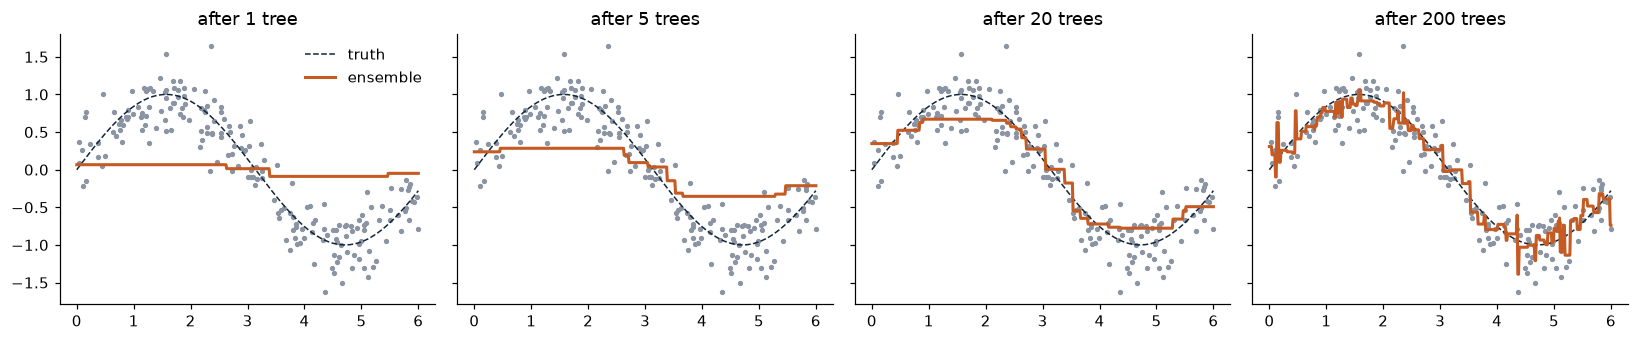

In [10]:
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 6, 200)); t = np.sin(x) + 0.3 * rng.standard_normal(200)
xs = np.linspace(0, 6, 500)

gbr = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=0).fit(x[:, None], t)
stages = list(gbr.staged_predict(xs[:, None]))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, m in zip(axes, [1, 5, 20, 200]):
    ax.scatter(x, t, s=6, color=GREY)
    ax.plot(xs, np.sin(xs), color=NAVY, lw=1, ls="--", label="truth")
    ax.plot(xs, stages[m - 1], color=ORANGE, lw=2, label="ensemble")
    ax.set_title(f"after {m} tree{'s' if m > 1 else ''}")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

Because it keeps chasing errors, boosting will eventually fit the noise. The learning rate $\eta$ and the number of rounds trade off against each other; **early stopping** on a validation set picks the number of rounds for you.

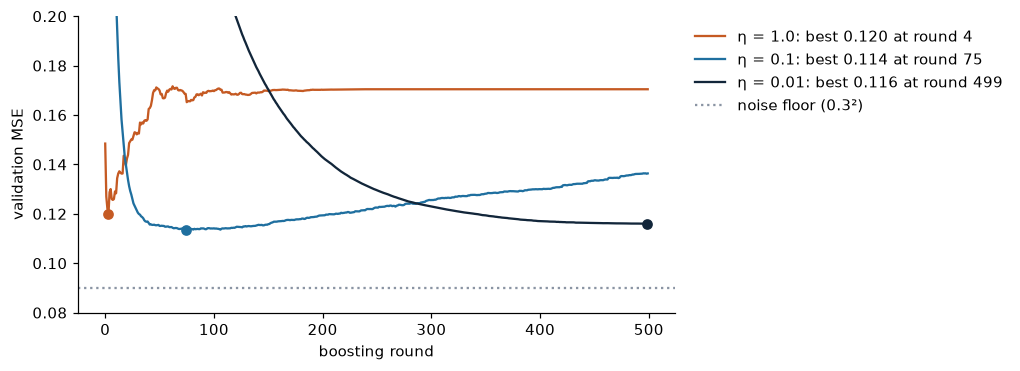

In [11]:
x_val = rng.uniform(0, 6, 200); t_val = np.sin(x_val) + 0.3 * rng.standard_normal(200)

fig, ax = plt.subplots(figsize=(7, 3.5))
for lr, color in [(1.0, ORANGE), (0.1, BLUE), (0.01, NAVY)]:
    model = GradientBoostingRegressor(n_estimators=500, learning_rate=lr, max_depth=2, random_state=0).fit(x[:, None], t)
    val_mse = [np.mean((p - t_val) ** 2) for p in model.staged_predict(x_val[:, None])]
    best = int(np.argmin(val_mse))
    ax.plot(val_mse, color=color, label=f"η = {lr}: best {val_mse[best]:.3f} at round {best + 1}")
    ax.plot(best, val_mse[best], "o", color=color)
ax.axhline(0.09, color=GREY, ls=":", label="noise floor (0.3²)")
ax.set_ylim(0.08, 0.2); ax.set_xlabel("boosting round"); ax.set_ylabel("validation MSE"); ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

Big steps overfit fast; tiny steps need many rounds. A small $\eta$ plus early stopping is the usual recipe (XGBoost, LightGBM and `HistGradientBoostingClassifier` all support it).

## 5 · Stacking

Now a harder, 20-feature tabular problem, where our candidate models differ much more in quality.
Soft voting gives every member an equal say. **Stacking** instead trains a small meta-model on the members' predictions, so it can learn whom to trust.

In [12]:
X2, y2 = make_classification(n_samples=1500, n_features=20, n_informative=8, n_redundant=4,
                             flip_y=0.05, class_sep=0.8, random_state=1)
members2 = [
    ("logistic regression", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    ("k-NN",                make_pipeline(StandardScaler(), KNeighborsClassifier(15))),
    ("decision tree",       DecisionTreeClassifier(max_depth=6, random_state=0)),
    ("naive Bayes",         GaussianNB()),
    ("small neural net",    make_pipeline(StandardScaler(), MLPClassifier((32,), max_iter=800, random_state=0))),
]
for name, m in members2:
    evaluate(name, m, X2, y2, "5 stacking")
print("-" * 45)
evaluate("soft voting (equal weights)", VotingClassifier(members2, voting="soft"), X2, y2, "5 stacking")
_ = evaluate("stacking (logistic meta-model)", StackingClassifier(members2, final_estimator=LogisticRegression(), cv=5), X2, y2, "5 stacking")

logistic regression          0.759 ± 0.019
k-NN                         0.830 ± 0.018
decision tree                0.782 ± 0.028
naive Bayes                  0.740 ± 0.019


small neural net             0.853 ± 0.017
---------------------------------------------


soft voting (equal weights)  0.840 ± 0.021


stacking (logistic meta-model) 0.870 ± 0.017


✅ **Checkpoint 5a:** best member (small neural net) `0.853`, soft voting `0.840`, stacking `0.870`.

Two lessons in one table:

* **Soft voting lost to its best member.** Three weak members dragged the average down (pitfall: *a weak member drags the mean*).
* **Stacking beat every member.** Let's look at the weights it learned:

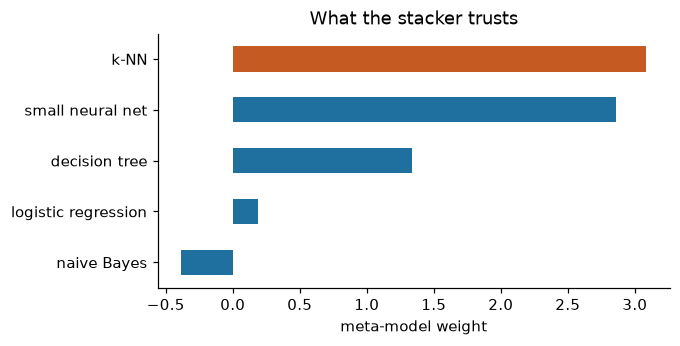

In [13]:
stack = StackingClassifier(members2, final_estimator=LogisticRegression(), cv=5).fit(X2, y2)
weights = pd.Series(stack.final_estimator_.coef_[0], index=[n for n, _ in members2]).sort_values()
ax = weights.plot.barh(color=[ORANGE if w == weights.max() else BLUE for w in weights], figsize=(6, 3))
ax.set_xlabel("meta-model weight"); ax.set_title("What the stacker trusts")
plt.show()

### The stacking trap: leakage

`StackingClassifier(cv=5)` trains the meta-model on **out-of-fold** predictions: each row is predicted by members that never saw it.
What if we skip that and use ordinary in-sample predictions? We add a fully grown decision tree, which is 100% accurate on its own training data.

In [14]:
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y2, test_size=0.3, random_state=0, stratify=y2)
members_leak = [(n, m) for n, m in members2 if n != "decision tree"] + [("deep tree", DecisionTreeClassifier(random_state=0))]
names = [n for n, _ in members_leak]

in_sample  = np.column_stack([m.fit(Xtr2, ytr2).predict_proba(Xtr2)[:, 1] for _, m in members_leak])
test_preds = np.column_stack([m.predict_proba(Xte2)[:, 1] for _, m in members_leak])
out_of_fold = np.column_stack([cross_val_predict(m, Xtr2, ytr2, cv=5, method="predict_proba")[:, 1] for _, m in members_leak])

naive  = LogisticRegression().fit(in_sample, ytr2)
proper = LogisticRegression().fit(out_of_fold, ytr2)

print("member test accuracy:", {n: round(m.score(Xte2, yte2), 3) for n, m in members_leak})
print(f"\nnaive stacking (in-sample):  test accuracy {naive.score(test_preds, yte2):.3f}")
print(f"proper stacking (out-of-fold): test accuracy {proper.score(test_preds, yte2):.3f}")
pd.DataFrame({"naive weights": naive.coef_[0], "out-of-fold weights": proper.coef_[0]}, index=names).round(2)

member test accuracy: {'logistic regression': 0.738, 'k-NN': 0.836, 'naive Bayes': 0.727, 'small neural net': 0.869, 'deep tree': 0.767}

naive stacking (in-sample):  test accuracy 0.767
proper stacking (out-of-fold): test accuracy 0.891


,naive weights,out-of-fold weights
logistic regression,0.29,0.82
k-NN,0.76,3.14
naive Bayes,0.23,-0.49
small neural net,3.13,2.24
deep tree,6.21,1.21


✅ **Checkpoint 5b:** naive stacking `0.767`, proper stacking `0.891`.

The naive meta-model sees a "perfect" deep tree and puts almost all its weight on it, so the ensemble is no better than that tree.
With out-of-fold predictions the tree is revealed as mediocre and the stacker leans on k-NN and the neural net instead.

## Summary

In [15]:
summary = pd.DataFrame(results)
summary["accuracy"] = summary["accuracy"].map("{:.3f}".format) + " ± " + summary.pop("std").map("{:.3f}".format)
summary.set_index(["part", "model"])

accuracy
part       model                                        
2 voting   logistic (poly 3)               0.882 ± 0.023
           decision tree                   0.872 ± 0.025
           k-NN (k=25)                     0.891 ± 0.021
           hard voting                     0.887 ± 0.022
           soft voting                     0.890 ± 0.020
3 bagging  one deep tree                   0.836 ± 0.021
           bagging, 100 trees              0.875 ± 0.015
           random forest, 100 trees        0.885 ± 0.019
4 boosting one stump                       0.798 ± 0.034
           AdaBoost, 200 stumps            0.880 ± 0.021
           gradient boosting, 100 trees    0.887 ± 0.018
5 stacking logistic regression             0.759 ± 0.019
           k-NN                            0.830 ± 0.018
           decision tree                   0.782 ± 0.028
           naive Bayes                     0.740 ± 0.019
           small neural net                0.853 ± 0.017
           soft voting (equal weights)     0.840 ± 0.021
           stacking (logistic meta-model)  0.870 ± 0.017

| Method | What we saw |
|---|---|
| Averaging | The gain is capped by how correlated the members are (ρ). |
| Voting | Beats the average member and gets close to the best one without knowing which that is. |
| Bagging / RF | Turns one jagged, overfit tree into a smooth, accurate model. More trees never hurt. |
| Boosting | Turns 80%-accurate stumps into an 88% model. Needs a small learning rate and early stopping. |
| Stacking | Learns whom to trust, and beat every member. Only with out-of-fold predictions. |

**More to try:** change `noise=0.35` in `make_moons`, drop the neural net from `members2`, or set `max_features=None` in the random forest (which turns it back into plain bagging).

**Learn more:** scikit-learn ensemble guide (https://scikit-learn.org/stable/modules/ensemble.html).